# DDS-8555 Assignment 4 — Build Non-Linear Models Part 2


## Part 1 — Conceptual Question 3 (ISLP p. 326)


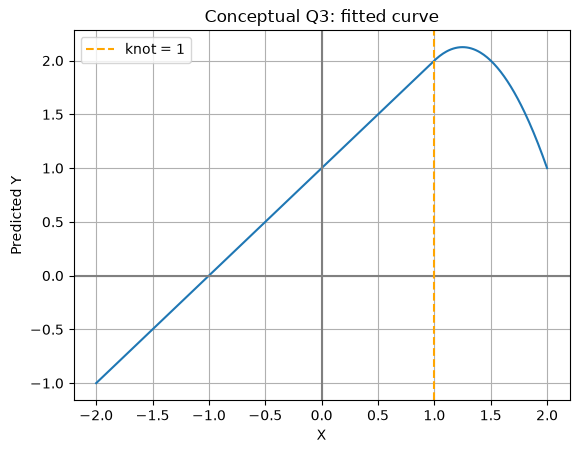

At x=1: y=2; slope=1
Other quadratic root: 2.2807764064044154 (outside [-2,2])


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
x = np.linspace(-2, 2, 400)
y = 1 + x - 2*np.maximum(x-1, 0)**2
plt.plot(x,y)
plt.axhline(0,color='gray'); plt.axvline(0,color='gray')
plt.axvline(1,color='orange',linestyle='--',label='knot = 1')
plt.title('Conceptual Q3: fitted curve');plt.xlabel('X');plt.ylabel('Predicted Y');plt.grid();plt.legend();plt.show()
print('At x=1: y=2; slope=1')
print('Other quadratic root:',(5+np.sqrt(17))/4,'(outside [-2,2])')


## Part 2 — Applied Question 8 (ISLP p. 327)

horsepower    0
mpg           0
dtype: int64
Linear RMSE: 4.707 R2: 0.566
Polynomial (degree 2) RMSE: 4.291 R2: 0.639
Cubic spline RMSE: 4.227 R2: 0.65


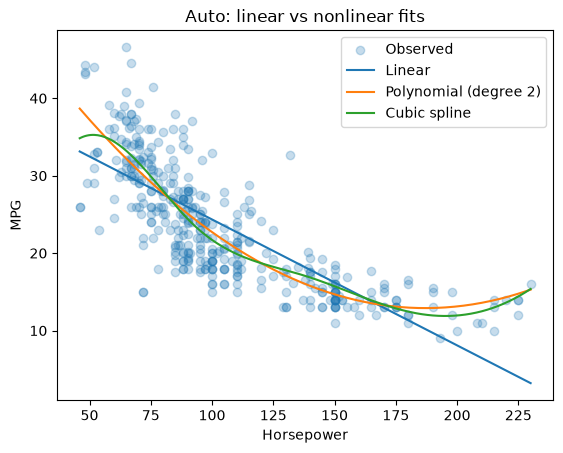

In [2]:
from ISLP import load_data
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

auto = load_data('Auto')
print(auto[['horsepower','mpg']].isna().sum())
auto = auto[['horsepower','mpg']].dropna()
Xa = auto[['horsepower']]; ya = auto['mpg']
Xa_train, Xa_val, ya_train, ya_val = train_test_split(Xa,ya,test_size=.2,random_state=42)
models_auto = {
    'Linear': LinearRegression(),
    'Polynomial (degree 2)': make_pipeline(PolynomialFeatures(2,include_bias=False),LinearRegression()),
    'Cubic spline': make_pipeline(SplineTransformer(n_knots=5,degree=3),LinearRegression())
}
for name,m in models_auto.items():
    m.fit(Xa_train,ya_train)
    pred=m.predict(Xa_val)
    print(name,'RMSE:',round(np.sqrt(mean_squared_error(ya_val,pred)),3),'R2:',round(r2_score(ya_val,pred),3))
xx = pd.DataFrame({'horsepower':np.linspace(Xa.horsepower.min(),Xa.horsepower.max(),250)})
plt.scatter(Xa.horsepower,ya,alpha=.25,label='Observed')
for name,m in models_auto.items():plt.plot(xx.horsepower,m.predict(xx),label=name)
plt.xlabel('Horsepower');plt.ylabel('MPG');plt.title('Auto: linear vs nonlinear fits');plt.legend();plt.show()


**Finding:** Yes, the relationship bends. MPG drops steeply up to about 100 horsepower and then levels off. The straight line has the highest validation RMSE (4.707, $R^2$=.566). The quadratic (4.291, $R^2$=.639) and cubic spline (4.227, $R^2$=.650) cut error by about 9–10%. Because the nonlinear fits clearly beat the linear one on held-out data, there is evidence of a nonlinear relationship. The quadratic is the simpler choice with nearly the same accuracy; the spline wiggles at the low-horsepower edge, where the data are sparse.

## Part 3 — Kaggle Abalone: prepare data and EDA

Training file: C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-4\playground-series-s4e4\train.csv
Test file: C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-4\playground-series-s4e4\test.csv
Train: (90615, 10) Test: (60411, 9)
Missing values in train:
id                0
Sex               0
Length            0
Diameter          0
Height            0
Whole weight      0
Whole weight.1    0
Whole weight.2    0
Shell weight      0
Rings             0
dtype: int64
Missing values in test:
id                0
Sex               0
Length            0
Diameter          0
Height            0
Whole weight      0
Whole weight.1    0
Whole weight.2    0
Shell weight      0
dtype: int64


,id,Sex,Length,Diameter,Height,Whole weight,Whole weight.1,Whole weight.2,Shell weight,Rings
0,0,F,0.550,0.430,0.150,0.7715,0.3285,0.1465,0.2400,11
1,1,F,0.630,0.490,0.145,1.1300,0.4580,0.2765,0.3200,11
2,2,I,0.160,0.110,0.025,0.0210,0.0055,0.0030,0.0050,6
3,3,M,0.595,0.475,0.150,0.9145,0.3755,0.2055,0.2500,10
4,4,I,0.555,0.425,0.130,0.7820,0.3695,0.1600,0.1975,9


,id,Length,Diameter,Height,Whole weight,Whole weight.1,Whole weight.2,Shell weight,Rings
count,90615.000000,90615.000000,90615.000000,90615.000000,90615.000000,90615.000000,90615.000000,90615.000000,90615.000000
mean,45307.000000,0.517098,0.401679,0.135464,0.789035,0.340778,0.169422,0.225898,9.696794
std,26158.441658,0.118217,0.098026,0.038008,0.457671,0.204428,0.100909,0.130203,3.176221
min,0.000000,0.075000,0.055000,0.000000,0.002000,0.001000,0.000500,0.001500,1.000000
25%,22653.500000,0.445000,0.345000,0.110000,0.419000,0.177500,0.086500,0.120000,8.000000
50%,45307.000000,0.545000,0.425000,0.140000,0.799500,0.330000,0.166000,0.225000,9.000000
75%,67960.500000,0.600000,0.470000,0.160000,1.067500,0.463000,0.232500,0.305000,11.000000
max,90614.000000,0.815000,0.650000,1.130000,2.825500,1.488000,0.760000,1.005000,29.000000


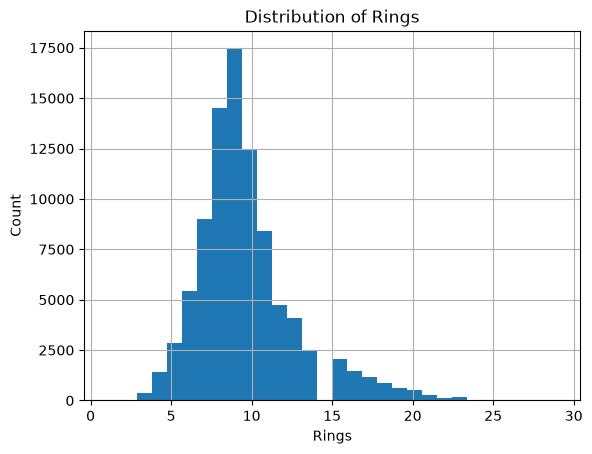

In [3]:
from pathlib import Path

DATA_DIR = Path(r"C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-4\playground-series-s4e4")

# Use train.csv/test.csv when available; also accept previously downloaded names.
def find_csv(stem):
    preferred = DATA_DIR / f"{stem}.csv"
    if preferred.exists():
        return preferred
    matches = sorted(DATA_DIR.glob(f"{stem}(*).csv"))
    if matches:
        return matches[0]
    raise FileNotFoundError(f"Cannot find {stem}.csv in {DATA_DIR}")

train_path = find_csv("train")
test_path = find_csv("test")
print("Training file:", train_path)
print("Test file:", test_path)

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
print("Train:", train.shape, "Test:", test.shape)
print("Missing values in train:")
print(train.isna().sum())
print("Missing values in test:")
print(test.isna().sum())
display(train.head())
display(train.describe())
train["Rings"].hist(bins=30)
plt.title("Distribution of Rings")
plt.xlabel("Rings")
plt.ylabel("Count")
plt.show()

### Prepare predictors and validation data


In [4]:
X = pd.get_dummies(train.drop(columns=['id','Rings']),columns=['Sex'],dtype=int)
y = train['Rings']
X_kaggle = pd.get_dummies(test.drop(columns=['id']),columns=['Sex'],dtype=int)
X_kaggle = X_kaggle.reindex(columns=X.columns,fill_value=0)
medians = X.median(numeric_only=True)
X = X.fillna(medians); X_kaggle = X_kaggle.fillna(medians)
X_train,X_val,y_train,y_val = train_test_split(X,y,test_size=.2,random_state=42)
print(X_train.shape,X_val.shape)


(72492, 10) (18123, 10)


### Model 1 — Polynomial regression (degree 2)


In [5]:
from sklearn.preprocessing import StandardScaler
polynomial = make_pipeline(PolynomialFeatures(degree=2,include_bias=False),StandardScaler(),Ridge(alpha=10))
polynomial.fit(X_train,y_train)
pred_poly = polynomial.predict(X_val)
rmse_poly = np.sqrt(mean_squared_error(y_val,pred_poly))
print('Polynomial RMSE:',round(rmse_poly,4),'R2:',round(r2_score(y_val,pred_poly),4))


Polynomial RMSE: 1.9434 R2: 0.6323


### Model 2 — Cubic spline regression


In [6]:
from sklearn.compose import ColumnTransformer
numeric_cols = [c for c in X.columns if not c.startswith('Sex_')]
sex_cols = [c for c in X.columns if c.startswith('Sex_')]
transform = ColumnTransformer([
    ('splines',make_pipeline(SplineTransformer(n_knots=5,degree=3),StandardScaler()),numeric_cols),
    ('sex','passthrough',sex_cols)
])
spline = make_pipeline(transform,Ridge(alpha=10))
spline.fit(X_train,y_train)
pred_spline = spline.predict(X_val)
rmse_spline = np.sqrt(mean_squared_error(y_val,pred_spline))
print('Spline RMSE:',round(rmse_spline,4),'R2:',round(r2_score(y_val,pred_spline),4))


Spline RMSE: 1.9544 R2: 0.6281


### Compare and check residuals

,Model,RMSE,R2
0,Polynomial,1.943418,0.632327
1,Cubic spline,1.954443,0.628143


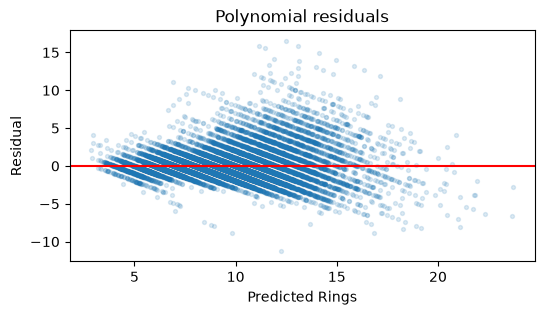

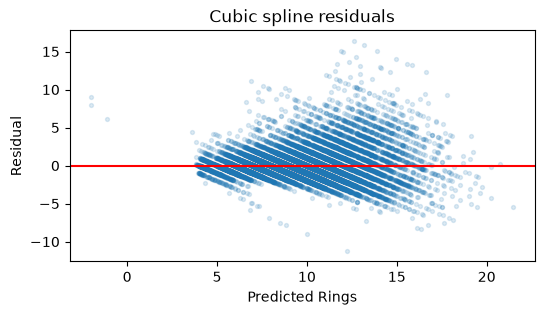

Best validation RMSE: Polynomial


In [7]:
results = pd.DataFrame({'Model':['Polynomial','Cubic spline'],
                        'RMSE':[rmse_poly,rmse_spline],
                        'R2':[r2_score(y_val,pred_poly),r2_score(y_val,pred_spline)]})
display(results)
for name,pred in [('Polynomial',pred_poly),('Cubic spline',pred_spline)]:
    plt.figure(figsize=(6,3))
    plt.scatter(pred,y_val-pred,alpha=.15,s=8)
    plt.axhline(0,color='red');plt.xlabel('Predicted Rings');plt.ylabel('Residual')
    plt.title(name+' residuals');plt.show()
print('Best validation RMSE:',results.loc[results.RMSE.idxmin(),'Model'])


**Interpretation:** The degree-2 polynomial has the lower validation RMSE (1.943 vs 1.954 rings; $R^2$ ≈ .63 for both). It also scored better on Kaggle (RMSLE 0.155 vs 0.160). The polynomial includes pairwise interactions, which suggests that the size and weight measurements matter in combination; the additive spline gives each predictor its own curve but misses those interactions.

**Assumptions:** Residuals center on zero, but their spread grows as predicted Rings increases. This violates the constant-variance assumption, and old abalone (high ring counts) are under-predicted, which shows up as a long upper tail. The predictors are highly collinear (the length and weight measures are strongly correlated), so the ridge penalty is used and single coefficients are not interpreted. Rows come from a synthetic Kaggle dataset, so independence cannot be checked from these plots, and the residuals are not normal because of the skewed target. The spline produced a few negative predictions; these are clipped at 0 in the submission files. Validation metrics are not Kaggle scores, because the test labels are hidden. A natural next step is to model $\log(1+\text{Rings})$ to match the RMSLE metric and stabilize the variance.

### Create two Kaggle CSV submissions

In [8]:
polynomial.fit(X, y)
spline.fit(X, y)

submission_poly = pd.DataFrame({
    "id": test["id"],
    "Rings": np.maximum(0, polynomial.predict(X_kaggle))
})
submission_spline = pd.DataFrame({
    "id": test["id"],
    "Rings": np.maximum(0, spline.predict(X_kaggle))
})

poly_file = DATA_DIR / "abalone_polynomial_assignment4.csv"
spline_file = DATA_DIR / "abalone_spline_assignment4.csv"
submission_poly.to_csv(poly_file, index=False)
submission_spline.to_csv(spline_file, index=False)

for output_file in [poly_file, spline_file]:
    result = pd.read_csv(output_file)
    assert list(result.columns) == ["id", "Rings"]
    assert len(result) == len(test)
    assert result.notna().all().all()
    print("Saved:", output_file)
    print(result.head())

Saved: C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-4\playground-series-s4e4\abalone_polynomial_assignment4.csv
      id      Rings
0  90615   9.056898
1  90616   9.769565
2  90617  10.454686
3  90618  10.237519
4  90619   7.664354
Saved: C:\Users\tsher\OneDrive\Desktop\National University\Classes\DDS-8555\Assignment-4\playground-series-s4e4\abalone_spline_assignment4.csv
      id      Rings
0  90615   8.308353
1  90616   9.746949
2  90617  10.679174
3  90618  10.442658
4  90619   7.807224
